# Emissions Inventory: Data Understanding

**Purpose.** Before designing the emissions assistant, I want to know what the client's data contains, how reliable it is,
and what that means for the solution. This notebook covers the three inventory CSVs only (`scope1.csv`, `scope2.csv`, `scope3.csv`).
The PDFs (GHG Protocol and peer reports) are handled separately in the knowledge-base and benchmarking work.

**Background (no carbon-accounting experience needed)**
- Each row is an *activity* multiplied by an *emission factor*, giving tonnes of CO2-equivalent (tCO2e): `CO2e = amount x emission factor`.
- **Scope 1**: direct emissions from the company's own operations (boilers, vehicles, industrial process, refrigerant leaks).
- **Scope 2**: indirect emissions from purchased energy (electricity, steam).
- **Scope 3**: all other value-chain emissions (suppliers, travel, product use), grouped into 15 official categories.

**Outline**
1. Overview and reporting periods
2. A consistency check that applies to all three files
3. Scope 1, 4. Scope 2, 5. Scope 3
6. Issues found and how they shape the solution

All figures are computed from the CSVs when the notebook runs. The only LLM-supplied inputs are the Scope 3 mappings, which are
declared explicitly in section 5 so they can be challenged.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.float_format = "{:,.2f}".format
pd.options.display.width = 140
plt.rcParams.update({"figure.figsize": (7, 3.2), "axes.spines.top": False, "axes.spines.right": False})

# Works whether the notebook is run from the repo root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
s1 = pd.read_csv(ROOT / "data/scope1.csv", parse_dates=["Date"])
s2 = pd.read_csv(ROOT / "data/scope2.csv", parse_dates=["Date"])
s3 = pd.read_csv(ROOT / "data/scope3.csv", parse_dates=["Date"])

## 1. Overview: three files, three different shapes

In [2]:
scopes = {"Scope 1": s1, "Scope 2": s2, "Scope 3": s3}

overview = pd.DataFrame({
    "rows": [len(d) for d in scopes.values()],
    "first month": [d.Date.min().strftime("%Y-%m") for d in scopes.values()],
    "last month": [d.Date.max().strftime("%Y-%m") for d in scopes.values()],
    "months covered": [d.Date.dt.to_period("M").nunique() for d in scopes.values()],
    "null cells": [int(d.isna().sum().sum()) for d in scopes.values()],
    "duplicate rows": [int(d.duplicated().sum()) for d in scopes.values()],
    "reported tCO2e": [d.CO2e_Tonnes.sum() for d in scopes.values()],
}, index=list(scopes))

# Simple annualisation (x 12 / months covered). An estimate: it assumes no seasonality.
overview["annualised tCO2e"] = overview["reported tCO2e"] * 12 / overview["months covered"]
overview["% of annualised total"] = overview["annualised tCO2e"] / overview["annualised tCO2e"].sum() * 100
overview["% of reported total"] = overview["reported tCO2e"] / overview["reported tCO2e"].sum() * 100
overview

,rows,first month,last month,months covered,null cells,duplicate rows,reported tCO2e,annualised tCO2e,% of annualised total,% of reported total
Scope 1,18,2024-01,2024-03,3,0,0,"1,692.47","6,769.88",1.73,0.45
Scope 2,18,2024-01,2024-03,3,0,0,"2,505.04","10,020.16",2.56,0.66
Scope 3,1000,2024-01,2024-12,12,0,0,"374,485.51","374,485.51",95.71,98.89


**Findings**
- **Basic hygiene is good**: no missing values and no duplicates. The problems are about meaning, not formatting.
- **Reporting periods do not match.** Scope 1 and 2 cover January to March 2024 only, while Scope 3 covers the full year.
  Summing the three totals mixes 3 and 12 months, so every cross-scope figure needs a stated basis.
- **Scope 3 dominates either way** (96% annualised, 99% as reported), so the *ranking* of the scopes is reliable even though absolute shares are not.
- Scope 1 and 2 have 18 rows each and can be reviewed row by row. Scope 3 has 1,000 rows, which is large enough for statistical checks.

**Implication for the solution:** present totals both as reported and annualised, and label which one is shown.

## 2. Does the arithmetic hold? (applies to all three files)

The files give no unit for `Emission_Factor`, so I test `reported / (amount x factor)`.
A ratio of 1 means the factor is in tonnes per unit, and 0.001 means kg per unit.

In [3]:
def unit_ratio(df, amount_col):
    # reported tonnes divided by amount x factor; reveals the implicit unit of the factor
    return df.CO2e_Tonnes / (df[amount_col] * df.Emission_Factor)

s1["ratio"] = unit_ratio(s1, "Consumption_Amount")
s2["ratio"] = unit_ratio(s2, "Consumption_Amount")
s3["ratio"] = unit_ratio(s3, "Spend_Amount")

pd.concat([
    s1.groupby("Fuel_Type").ratio.agg(["min", "max"]).assign(scope="1").rename_axis("source"),
    s2.groupby("Energy_Type").ratio.agg(["min", "max"]).assign(scope="2").rename_axis("source"),
    pd.DataFrame({"min": [s3.ratio.min()], "max": [s3.ratio.max()], "scope": "3"}, index=["all spend rows"]),
]).style.format({"min": "{:.4f}", "max": "{:.4f}"})

,min,max,scope
Cement Production,1.0000,1.0000,1
Coal,1.0000,1.0000,1
Diesel,0.0010,0.0010,1
Gasoline,0.0010,0.0010,1
Natural Gas,0.0010,0.0010,1
Refrigerants,0.0010,0.0010,1
Electricity,0.0010,0.0010,2
Steam,1.0000,1.0000,2
all spend rows,0.0010,0.0010,3


**Findings**
- **The arithmetic is correct on every row.** The ratio is 1 or 0.001 within rounding, so there are no calculation errors.
- **The factor units are mixed and undocumented.** Coal, cement and steam factors are tonnes per unit. Gas, diesel, gasoline, refrigerant, electricity and all Scope 3 factors are kg per unit.
  Reusing the factor column without knowing this would be wrong by a factor of 1,000.
- **All of Scope 3 is spend-based** (dollars multiplied by a generic factor), which is the least accurate calculation method.

**Implication:** any recalculation tool must carry the unit explicitly, and the quality report should flag the missing unit.

## 3. Scope 1: direct emissions (18 rows, Jan-Mar 2024)

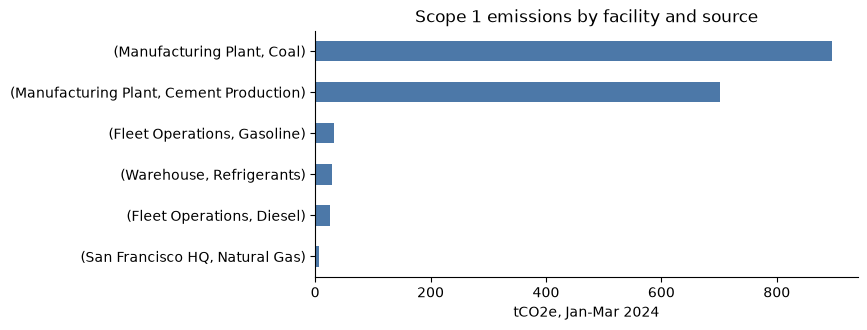

,% of Scope 1
Facility,
Fleet Operations,3.50
Manufacturing Plant,94.40
San Francisco HQ,0.40
Warehouse,1.70


In [4]:
by_source = s1.groupby(["Facility", "Fuel_Type"]).CO2e_Tonnes.sum().sort_values()
ax = by_source.plot.barh(color="#4C78A8")
ax.set_xlabel("tCO2e, Jan-Mar 2024"); ax.set_ylabel(""); ax.set_title("Scope 1 emissions by facility and source")
plt.show()

s1.groupby("Facility").CO2e_Tonnes.sum().pipe(lambda x: x / x.sum() * 100).round(1).to_frame("% of Scope 1")

**Findings**
- **The Manufacturing Plant accounts for about 94% of Scope 1**, from coal boilers and cement process emissions. Fleet, HQ gas and refrigerants are minor.
- The data is clean but thin: three months per source, so no seasonality or trend can be assessed.
- Missing metadata: factor source, year and unit, and the global-warming-potential table behind the refrigerant factor (3,922).

**Implication:** analysis and recommendations should concentrate on the plant.

## 4. Scope 2: purchased energy (18 rows, Jan-Mar 2024)

This scope gets the closest look because the GHG Protocol has specific method requirements for it (location-based and market-based reporting).

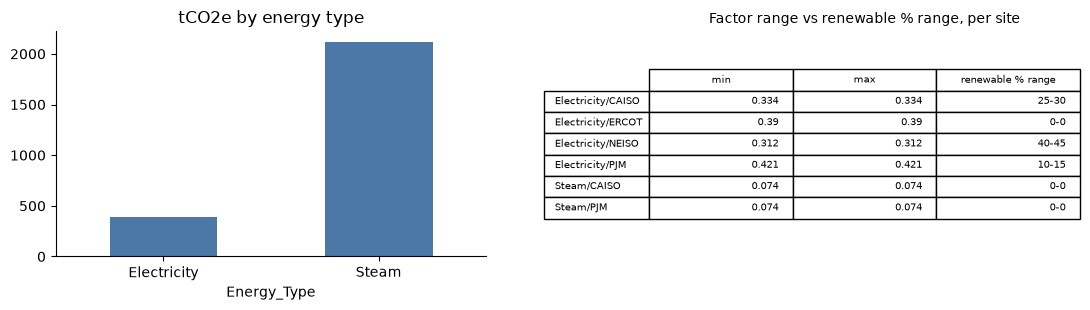

Steam share of Scope 2: 84%


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))

# Left: where the emissions come from
s2.groupby("Energy_Type").CO2e_Tonnes.sum().plot.bar(ax=ax[0], color="#4C78A8", rot=0, title="tCO2e by energy type")

# Right: does the emission factor ever react to the recorded renewable share?
grp = s2.groupby(["Energy_Type", "Grid_Region"])
tbl = grp.Emission_Factor.agg(["min", "max"])
tbl["renewable % range"] = grp.Renewable_Percentage.agg(lambda x: f"{x.min()}-{x.max()}")
ax[1].axis("off")
ax[1].set_title("Factor range vs renewable % range, per site", fontsize=10)
ax[1].table(cellText=tbl.round(3).astype(str).values, colLabels=list(tbl.columns),
            rowLabels=[f"{a}/{b}" for a, b in tbl.index], loc="center").scale(1, 1.4)
plt.tight_layout(); plt.show()

steam_share = s2[s2.Energy_Type == "Steam"].CO2e_Tonnes.sum() / s2.CO2e_Tonnes.sum()
print(f"Steam share of Scope 2: {steam_share:.0%}")

**Findings**
- **Steam is about 84% of Scope 2** and uses a single generic factor (0.074) for two unrelated sites.
  It also carries electricity grid regions (CAISO, PJM), which do not apply to steam.
- **`Renewable_Percentage` is recorded but never applied.** The factor's min and max are identical for every site even though renewables rise from 25% to 30% at HQ and 10% to 15% at the plant.
- **Only one method is reported (location-based).** The GHG Protocol also expects a market-based figure, which requires evidence such as certificates or contracts. None is present.
- **Possible double counting.** The plant burns coal for boiler operations (Scope 1) and also buys process-heating steam (Scope 2).
  If that steam is generated by its own boilers, it is counted twice. This is a question for the client, not a confirmed error.
- Grid factors are one constant per region, with no source or year.

**Implication:** the Scope 2 quality assessment should lead with method disclosure and the steam factor, and phrase double counting as a question to confirm.

## 5. Scope 3: value chain (1,000 rows, 96-99% of the total)

In [6]:
print("Constant columns (carry no information):", [c for c in s3.columns if s3[c].nunique() == 1])
print("Distinct activities:", s3.Activity_Description.nunique(),
      "| suppliers:", s3.Supplier.nunique(), "| categories:", s3.Category.nunique())

Constant columns (carry no information): ['Spend_Currency', 'Category_Details']
Distinct activities: 10 | suppliers: 8 | categories: 15


### Domain assumptions used in this section
The files do not state which activity belongs to which Scope 3 category, or which supplier would plausibly provide which activity.
The three lookups below come from **LLM domain knowledge** (the GHG Protocol Scope 3 category list and common-sense reading of the supplier names). They are not in the provided files.
Every "label matches" and "supplier plausible" figure below depends on them, so a domain expert should review them before they are relied on.

In [7]:
# The 15 official Scope 3 category names (LLM knowledge of the GHG Protocol Scope 3 Standard; not in the provided files).
SCOPE3_CATEGORIES = {
    1: "Purchased goods and services", 2: "Capital goods", 3: "Fuel- and energy-related activities",
    4: "Upstream transportation and distribution", 5: "Waste generated in operations", 6: "Business travel",
    7: "Employee commuting", 8: "Upstream leased assets", 9: "Downstream transportation and distribution",
    10: "Processing of sold products", 11: "Use of sold products", 12: "End-of-life treatment of sold products",
    13: "Downstream leased assets", 14: "Franchises", 15: "Investments",
}
# LLM-assigned: the category each activity should belong to.
EXPECTED_CATEGORY = {
    "Raw Materials - Steel": 1, "Raw Materials - Aluminum": 1, "Packaging Materials": 1, "Office Supplies": 1,
    "IT Hardware": 2, "Manufacturing Equipment": 2, "Inbound Logistics - Truck": 4,
    "Business Travel - Air": 6, "Employee Commuting": 7, "Product Use Phase": 11,
}
# LLM-assigned: activities each supplier could plausibly provide, judged from its name.
EXPECTED_SUPPLIER_ACTIVITIES = {
    "SteelCorp Inc": {"Raw Materials - Steel"}, "MetalSupply Co": {"Raw Materials - Steel", "Raw Materials - Aluminum"},
    "PackagePro Ltd": {"Packaging Materials"}, "OfficeMax": {"Office Supplies", "IT Hardware"},
    "TechEquip Corp": {"IT Hardware", "Manufacturing Equipment"}, "Corporate Travel": {"Business Travel - Air"},
    "LogisticsPro": {"Inbound Logistics - Truck"}, "WasteManagement Co": set(),   # no waste activity exists in the data
}

### 5a. Do the category labels carry information?
Scope 3 categories are defined by the type of activity (for example, air travel is Category 6 and commuting is Category 7).
If the labels were meaningful, each activity would sit almost entirely in one category.
Using the mapping above, the heatmap shows how many rows fall in each (activity, category) cell, with the expected category outlined in red.

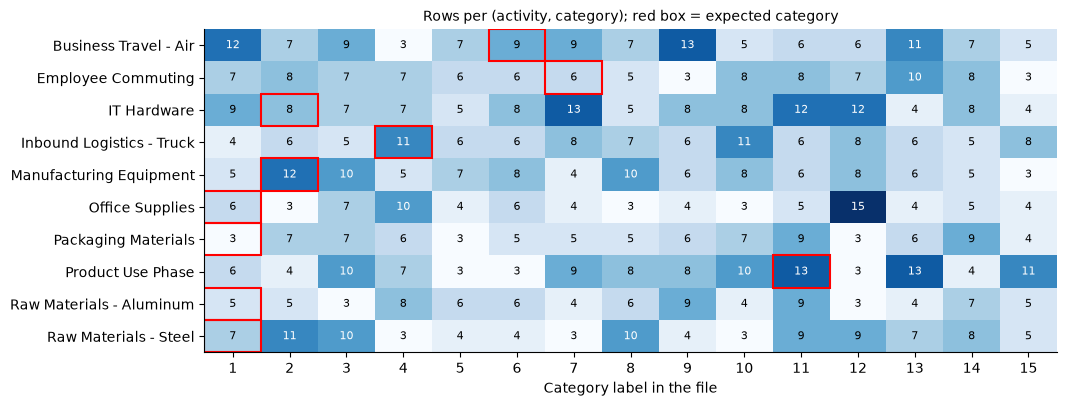

Label matches the expected category on 8% of rows (random assignment among 15 categories would give about 7%)


In [8]:
s3["cat"] = s3.Category.str.extract(r"(\d+)").astype(int)
s3["expected_cat"] = s3.Activity_Description.map(EXPECTED_CATEGORY)
s3["label_ok"] = s3.cat == s3.expected_cat

xt = pd.crosstab(s3.Activity_Description, s3.cat)
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.imshow(xt.values, cmap="Blues", aspect="auto")
# print the row count inside each cell (white text on dark cells for contrast)
for i in range(xt.shape[0]):
    for j in range(xt.shape[1]):
        v = xt.values[i, j]
        ax.text(j, i, v, ha="center", va="center", fontsize=8, color="white" if v > xt.values.max() * 0.6 else "black")
ax.set_xticks(range(15), xt.columns); ax.set_yticks(range(len(xt)), xt.index)
ax.set_xlabel("Category label in the file")
ax.set_title("Rows per (activity, category); red box = expected category", fontsize=10)
for i, activity in enumerate(xt.index):
    ax.add_patch(plt.Rectangle((EXPECTED_CATEGORY[activity] - 1 - .5, i - .5), 1, 1, fill=False, ec="red", lw=1.5))
plt.show()

print(f"Label matches the expected category on {s3.label_ok.mean():.0%} of rows "
      f"(random assignment among 15 categories would give about {1/15:.0%})")

**Finding:** every activity appears in all 15 categories, and the red boxes look no different from other cells.
Agreement is about 8%, which is what random assignment would produce. **The category label carries no usable information.**
I also ran a permutation test (shuffling the labels and comparing), which reached the same conclusion (p of about 0.3).

### 5b. The same question gives two different answers: which Scope 3 category is highest?

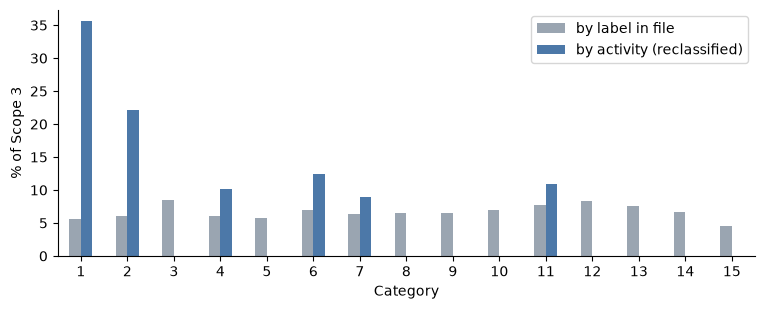

Top by label   : 3 Fuel- and energy-related activities (8.5%)
Top by activity: 1 Purchased goods and services (35.6%)
Share of tonnage labelled as downstream (categories 9-15): 48%


In [9]:
by_label = s3.groupby("cat").CO2e_Tonnes.sum()                 # trusting the label in the file
by_activity = s3.groupby("expected_cat").CO2e_Tonnes.sum()     # reclassified using the activity

cmp = pd.DataFrame({"by label in file": by_label, "by activity (reclassified)": by_activity}).fillna(0)
cmp = cmp / cmp.sum() * 100
ax = cmp.plot.bar(figsize=(9, 3.2), color=["#9aa5b1", "#4C78A8"], rot=0)
ax.set_ylabel("% of Scope 3"); ax.set_xlabel("Category")
plt.show()

print("Top by label   :", by_label.idxmax(), SCOPE3_CATEGORIES[by_label.idxmax()], f"({by_label.max()/by_label.sum():.1%})")
print("Top by activity:", by_activity.idxmax(), SCOPE3_CATEGORIES[by_activity.idxmax()], f"({by_activity.max()/by_activity.sum():.1%})")
print(f"Share of tonnage labelled as downstream (categories 9-15): {by_label[by_label.index >= 9].sum() / by_label.sum():.0%}")

**Finding:** by label, the categories are nearly flat and the "top" is Category 3 (fuel- and energy-related activities), which none of the 10 activities belongs to, so it is likely an artefact.
By activity, **Category 1 (purchased goods and services) is about 36%** and Category 2 (capital goods) about 22%.

**Implication:** the assistant should show both views and explain the difference, rather than give one confident answer.

### 5c. Suppliers, emission factors and quality labels

Supplier is plausible for the activity on 12% of rows


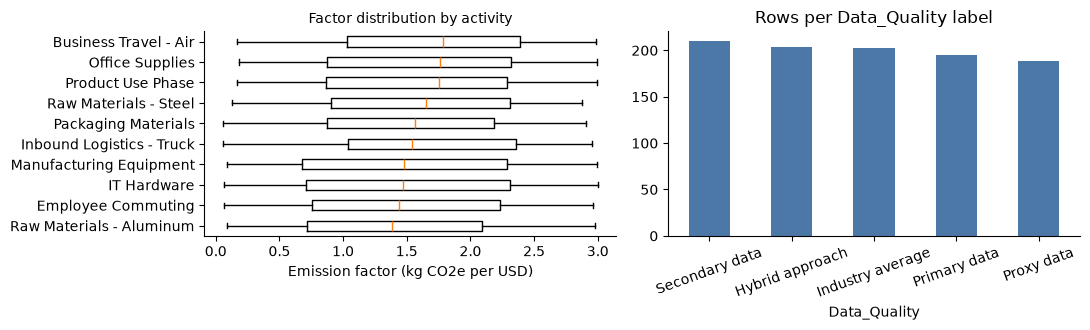

                           median  min  max  max / min
Activity_Description                                  
Raw Materials - Aluminum     1.38 0.09 2.98      34.28
Employee Commuting           1.44 0.07 2.96      44.24
IT Hardware                  1.47 0.06 3.00      46.14
Manufacturing Equipment      1.48 0.09 3.00      34.84
Inbound Logistics - Truck    1.54 0.06 2.95      50.90
Packaging Materials          1.57 0.06 2.91      48.47
Raw Materials - Steel        1.65 0.12 2.88      23.03
Product Use Phase            1.76 0.17 2.99      17.60
Office Supplies              1.76 0.19 3.00      16.12
Business Travel - Air        1.79 0.17 2.99      18.01

Correlation between spend and factor: -0.037


In [10]:
s3["supplier_ok"] = [a in EXPECTED_SUPPLIER_ACTIVITIES[s] for s, a in zip(s3.Supplier, s3.Activity_Description)]
print(f"Supplier is plausible for the activity on {s3.supplier_ok.mean():.0%} of rows")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))

# Left: spend-based factors should differ by sector (steel vs office supplies); do they?
order = s3.groupby("Activity_Description").Emission_Factor.median().sort_values().index
ax[0].boxplot([s3[s3.Activity_Description == a].Emission_Factor for a in order], orientation="horizontal", tick_labels=order)
ax[0].set_xlabel("Emission factor (kg CO2e per USD)"); ax[0].set_title("Factor distribution by activity", fontsize=10)

# Right: the Data_Quality label should reflect the calculation method
s3.Data_Quality.value_counts().plot.bar(ax=ax[1], color="#4C78A8", rot=20, title="Rows per Data_Quality label")
plt.tight_layout(); plt.show()

spread = s3.groupby("Activity_Description").Emission_Factor.agg(["median", "min", "max"])
spread["max / min"] = spread["max"] / spread["min"]
print(spread.sort_values("median").round(2).to_string())
print("\nCorrelation between spend and factor:", round(s3.Spend_Amount.corr(s3.Emission_Factor), 3))

**Findings**
- **Suppliers do not match activities.** For example, "Corporate Travel" supplies inbound trucking, and "WasteManagement Co" appears although the data contains no waste activity.
  A supplier-priority ranking therefore has weak footing.
- **Emission factors look randomly drawn.** Every activity has a similar median (1.4 to 1.8 kg per USD) and a very wide range (the largest value is 16 to 51 times the smallest, per the table), and spend and factor are uncorrelated.
  Real spend-based factors differ clearly by sector, so **Scope 3 totals are driven by arbitrary factors rather than real activity**.
- **`Data_Quality` is unreliable.** The five labels are spread evenly (about 20% each), and "Primary data" appears on rows that are spend multiplied by a generic factor, which contradicts its definition.
- **Downstream categories (9-15) hold roughly half the tonnage** by label. They depend on what the company *sells*, yet every row is calculated from purchase spend.
- Two columns are constant and carry no information: `Spend_Currency` and `Category_Details`.

**Implication:** Scope 3 totals should never be presented as precise, and recommendations should call for primary supplier data on the largest activities.

## 6. Summary: issues found and how they shape the solution

| # | Issue | Scope | Severity | How the solution responds |
|---|---|---|---|---|
| 1 | Periods differ (3 vs 12 months) | All | High | Show as-reported and annualised views, and label which is used |
| 2 | Factor units missing and mixed (kg vs tonnes) | 1, 2, 3 | Medium | Recalculation carries units explicitly; flagged in the quality report |
| 3 | Plant is about 94% of Scope 1 | 1 | Info | Focus analysis and recommendations on the plant |
| 4 | Renewable % recorded but not applied; no market-based figure | 2 | High | Quality check explains the dual-reporting expectation |
| 5 | Steam is about 84% of Scope 2 with one generic, electricity-region factor | 2 | High | Flag as the most influential and least specific factor |
| 6 | Possible Scope 1 / Scope 2 double counting at the plant | 1, 2 | Medium | Raise as a question to confirm, not as an error |
| 7 | Category labels no better than random (8% agreement) | 3 | High | Report both the label view and the activity view |
| 8 | Supplier and activity pairs implausible | 3 | Medium | Caveat the supplier ranking as weakly differentiated |
| 9 | Random-looking factors, spend-only method, contradictory `Data_Quality` | 3 | High | Never present Scope 3 totals as precise |

**Design principles that follow from the data**
1. **Numbers come from code, not from the LLM.** Totals, shares and rankings are computed by deterministic pandas/SQL tools, so they are exact and traceable.
2. **Quality assessment is rule-based.** The checks in this notebook become rules with evidence and a recommendation. The LLM explains and prioritises them.
3. **Every answer states its caveats**, such as the period mismatch and unreliable Scope 3 labels, because the data cannot support one confident number.
4. **The GHG Protocol document supports explanation and citation** (retrieval). Peer benchmarking is a separate step.

**Inputs to request from the client:** a full year of Scope 1 and 2 data; the source, year and unit of each emission factor;
market-based Scope 2 evidence (certificates, contracts); the plant's steam source; and a verified Scope 3 category for each row.

**Limitations of this analysis:** the Scope 3 mappings in section 5 are LLM-generated and not expert-verified, and the annualisation assumes no seasonality.